# Автоэнкодеры (ноутбук)

### **Векторные представления изображений с помощью Автоэнкодеров**

На этом занятии мы углубимся в концепцию **векторных представлений изображений**, или **эмбеддингов**. Эмбеддинг — это числовой вектор, который компактно и осмысленно описывает какой-либо объект (изображение, текст, аудио и т.д.). Наша цель — научиться получать такие векторы для изображений без необходимости в обширной ручной разметке данных.

Мы рассмотрим мощный инструмент для этой цели — **автоэнкодеры**. Автоэнкодеры — это тип нейронных сетей, предназначенных для обучения эффективных кодировок (эмбеддингов) входных данных. Они пытаются сжать входные данные в "латентное пространство" (вектор эмбеддинга), а затем реконструировать исходные данные из этого сжатого представления, что позволяет модели научиться извлекать наиболее важные признаки из данных.

В этом ноутбуке мы:
1. Построим и обучим простой **Автоэнкодер** на датасете MNIST.
2. Визуализируем, как автоэнкодер реконструирует изображения.
3. Покажем, как можно **генерировать новые изображения** путем интерполяции в латентном пространстве.
4. Введем концепцию **Denoising Autoencoder** (шумоподавляющего автоэнкодера) для повышения устойчивости модели к шуму и улучшения качества эмбеддингов.
5. Продемонстрируем, как эти автоматически полученные эмбеддинги могут использоваться для решения задач классификации с **ограниченным количеством размеченных данных**.


### Подготовка данных MNIST

Мы будем использовать датасет MNIST, который состоит из изображений рукописных цифр. Чтобы сделать задачу немного интереснее и увеличить размер изображений для автоэнкодера, мы масштабируем их до 64x64 пикселей.

In [1]:
#!g1.1
# Импортируем необходимые библиотеки
import torch # Основная библиотека для работы с тензорами и нейронными сетями
import torch.nn as nn # Модуль для построения нейронных сетей
from torchvision.datasets import MNIST # Датасет MNIST для рукописных цифр
import torchvision.transforms as T # Модуль для преобразований изображений

from torch.utils.data import DataLoader # Для загрузки данных батчами
from IPython.display import clear_output # Для очистки вывода в Jupyter/Colab
from tqdm import tqdm # Для отображения прогресса выполнения циклов
import matplotlib.pyplot as plt # Для построения графиков
from torch.optim import Adam # Оптимизатор Adam
import numpy as np # Для работы с массивами (в частности, для случайных выборок)
from PIL import Image # Для работы с изображениями (Pillow)
import math # Для математических операций (например, sqrt)
from torchvision.utils import make_grid # Для создания сетки из изображений

In [2]:
#!g1.1
# Определяем преобразования для изображений:
# 1. Изменяем размер изображения до 64x64 пикселей. Это увеличит детализацию и сделает
#    задачу для автоэнкодера более сложной, чем стандартные 28x28.
# 2. Преобразуем изображение из PIL Image в PyTorch Tensor.
mnist_transforms = T.Compose(
    [
        T.Resize((64, 64)),
        T.ToTensor(), # Преобразует изображение в тензор и нормализует пиксели до диапазона [0, 1]
    ]
)

# Загружаем обучающий датасет MNIST. Если его нет, он будет загружен автоматически.
train_dataset = MNIST('mnist', train=True, transform=mnist_transforms, download=True)
# Загружаем тестовый (валидационный) датасет MNIST.
valid_dataset = MNIST('mnist', train=False, transform=mnist_transforms, download=True)

# Создаем DataLoader'ы для удобной загрузки данных батчами:
# batch_size=64: Количество изображений в каждом батче.
# shuffle=True: Перемешивает данные в каждой эпохе для обучающего датасета,
#               чтобы модель не запоминала порядок.
# num_workers=8: Количество подпроцессов для загрузки данных (ускоряет).
# pin_memory=True: Загружает данные в "закрепленную" память, что может ускорить
#                  передачу данных на GPU.
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=8, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=64, shuffle=False, num_workers=8, pin_memory=True)

### Вспомогательные функции для обучения и визуализации

Для удобства обучения и оценки модели, а также для визуализации результатов, мы определим несколько функций.

#### `train(model)`: Функция для одной эпохи обучения модели

Эта функция реализует стандартный цикл обучения: проход по данным, вычисление потерь, обратное распространение ошибки и обновление весов. Отличительная особенность для автоэнкодера: нам не нужны метки `y`, так как он обучается на восстановление входного `x`.


In [3]:
#!g1.1
def train(model):
    model.train() # Переводим модель в режим обучения (активирует dropout, batchnorm и т.д.)

    train_loss = 0 # Переменная для накопления общей ошибки за эпоху

    # Итерируемся по обучающему DataLoader'у. tqdm добавляет красивую полосу прогресса.
    # В автоэнкодере нам не нужны метки (y), поэтому мы используем _ для их игнорирования.
    for x, _ in tqdm(train_loader, desc='Train'):
        x = x.to(device) # Перемещаем входные изображения на используемое устройство (GPU/CPU)

        optimizer.zero_grad() # Обнуляем градиенты перед началом нового шага оптимизации

        output = model(x) # Пропускаем изображение через модель (прямой проход)
        # Для автоэнкодера выход - это восстановленное изображение,
        # а целью является само входное изображение (x).
        loss = loss_fn(output, x) # Вычисляем ошибку между выходом модели и исходным изображением

        train_loss += loss.item() # Добавляем значение ошибки текущего батча к общей ошибке

        loss.backward() # Вычисляем градиенты для всех обучаемых параметров модели

        optimizer.step() # Обновляем веса модели с помощью оптимизатора

    train_loss /= len(train_loader) # Усредняем ошибку по всем батчам
    return train_loss

#### `evaluate(model, loader)`: Функция для оценки качества модели

Эта функция аналогична `train`, но не выполняет обновление весов. Она используется для измерения качества модели на валидационном наборе данных, чтобы отслеживать переобучение.

In [4]:
#!g1.1
@torch.inference_mode() # Декоратор для отключения вычисления градиентов,
                        # что экономит память и ускоряет вычисления во время оценки.
def evaluate(model, loader):
    model.eval() # Переводим модель в режим оценки (отключает dropout, замораживает batchnorm и т.д.)

    total_loss = 0 # Переменная для накопления общей ошибки

    for x, _ in tqdm(loader, desc='Evaluation'):
        x = x.to(device) # Перемещаем изображения на устройство

        output = model(x) # Прямой проход

        loss = loss_fn(output, x) # Вычисление ошибки

        total_loss += loss.item() # Накопление ошибки

    total_loss /= len(loader) # Усреднение ошибки
    return total_loss

#### `plot_stats(train_loss, valid_loss, title)`: Функция для построения графиков потерь

In [5]:
#!g1.1
def plot_stats(
    train_loss: list[float],
    valid_loss: list[float],
    title: str
):
    plt.figure(figsize=(16, 8)) # Создаем фигуру для графика с заданным размером

    plt.title(title + ' loss') # Устанавливаем заголовок графика

    plt.plot(train_loss, label='Train loss') # Рисуем график обучающей ошибки
    plt.plot(valid_loss, label='Valid loss') # Рисуем график валидационной ошибки
    plt.legend() # Отображаем легенду
    plt.grid() # Отображаем сетку

    plt.show() # Показываем график

#### `visualize(model, xs)`: Функция для визуализации предсказаний

Эта функция берет несколько входных изображений, пропускает их через модель, а затем отображает исходные и восстановленные изображения рядом для сравнения. `make_grid` из `torchvision.utils` очень удобна для создания одной большой картинки из батча маленьких.


In [6]:
#!g1.1
@torch.inference_mode()
def visualize(model, xs):
    model.eval() # Переводим модель в режим оценки

    to_pil = T.ToPILImage() # Преобразователь тензора в PIL Image для отображения

    # Получаем выход модели для входных изображений.
    # .cpu() - перемещаем тензоры обратно на CPU для дальнейшей обработки и отображения.
    outputs = model(xs.to(device)).cpu()
    
    plt.figure(figsize=(20, 4)) # Создаем фигуру для визуализации

    # Создаем сетку из изображений:
    # make_grid(xs[:10], nrow=10, pad_value=1): берем первые 10 исходных изображений,
    #                                           размещаем их в один ряд (10 картинок в ряду).
    #                                           pad_value=1 создает белые границы между изображениями.
    # make_grid(outputs[:10], nrow=10, pad_value=1): то же самое для 10 восстановленных изображений.
    # torch.cat(..., dim=1): объединяет две сетки (исходные и восстановленные) вертикально.
    # to_pil(...): преобразует объединенный тензор в PIL Image для вывода.
    plt.imshow(
        to_pil(
            torch.cat(
                (
                    make_grid(xs[:10], nrow=10, pad_value=1), # Исходные изображения
                    make_grid(outputs[:10], nrow=10, pad_value=1) # Восстановленные изображения
                ),
                dim=1 # Объединяем по вертикали (dim=1, так как make_grid создает [C, H, W] тензор)
            )
        )
    )
    
    plt.axis('off') # Отключаем оси координат для более чистого отображения

    plt.show() # Показываем изображение

#### `whole_train_valid_cycle(model, num_epochs, title)`: Основной цикл обучения и оценки

Эта функция объединяет все предыдущие шаги: обучение на одну эпоху, оценку, очистку вывода, визуализацию и построение графиков потерь.


In [7]:
#!g1.1
def whole_train_valid_cycle(model, num_epochs, title):
    train_loss_history, valid_loss_history = [], [] # Списки для хранения истории потерь

    for epoch in range(num_epochs):
        print(f"Epoch {epoch + 1}/{num_epochs}")
        train_loss = train(model) # Обучение на одну эпоху
        valid_loss = evaluate(model, valid_loader) # Оценка на валидационном наборе

        train_loss_history.append(train_loss)
        valid_loss_history.append(valid_loss)

        clear_output(wait=True) # Очищаем предыдущий вывод перед обновлением графиков
        
        # Визуализируем предсказания на первом батче валидационного набора
        visualize(model, next(iter(valid_loader))[0]) 

        # Строим графики потерь
        plot_stats(
            train_loss_history, valid_loss_history,
            title
        )

### Архитектура Автоэнкодера

Теперь давайте определим архитектуру нашего автоэнкодера. Он будет состоять из двух основных частей: **энкодера** (кодировщика) и **декодера** (декодировщика).

*   **Энкодер** будет сжимать входное изображение до латентного векторного представления (эмбеддинга).
*   **Декодер** будет восстанавливать изображение из этого латентного представления.

Мы будем использовать сверточные слои, `BatchNorm` для стабилизации обучения и `LeakyReLU` в качестве функции активации. Для уменьшения размерности в энкодере будем использовать свертки со `stride=2`, а для увеличения размерности в декодере — интерполяцию с последующими свертками.

#### `Block` класс: Базовый строительный блок для Энкодера и Декодера

Этот класс инкапсулирует общую структуру сверточного слоя, нормализации и активации, которая будет использоваться как в энкодере, так и в декодере. Флаг `upsample` позволит ему выполнять интерполяцию перед сверткой, когда он используется в декодере.


In [8]:
#!g1.1
class Block(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, stride: int = 1, upsample: bool = False):
        super().__init__()
        self.upsample = upsample # Флаг, указывающий, нужно ли делать интерполяцию (для декодера)

        # Сверточный слой
        # in_channels: количество входных каналов (например, 1 для ч/б MNIST)
        # out_channels: количество выходных каналов (глубина признаковых карт)
        # kernel_size: размер ядра свертки (3x3 в данном случае)
        # stride: шаг свертки. stride=2 уменьшает размер изображения в 2 раза
        # padding=1: добавляет 1 пиксель отступов по краям, чтобы размер выходной карты
        #            сохранялся при stride=1, или уменьшался ровно в 2 раза при stride=2.
        # bias=False: отключаем смещение, так как Batch Normalization все равно введет свое смещение.
        self.conv = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=1,
            bias=False
        )
        self.norm = nn.BatchNorm2d(out_channels) # Batch Normalization для стабилизации обучения
        self.act = nn.LeakyReLU(0.2) # Leaky ReLU активация: предотвращает "умирание" нейронов,
                                     # допуская небольшой отрицательный градиент для отрицательных входов.

    def forward(self, x):
        # Если блок используется в декодере и установлен флаг upsample,
        # то увеличиваем размер изображения в 2 раза перед сверткой.
        # mode='bilinear': используется билинейная интерполяция для гладкого увеличения.
        if self.upsample:
            x = nn.functional.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False, recompute_scale_factor=False)

        # Выполняем свертку, нормализацию и активацию.
        return self.act(self.norm(self.conv(x)))

#### `AutoEncoder` класс: Сборка полной архитектуры

Этот класс объединяет несколько блоков `Block` для создания энкодера и декодера, формируя полноценный автоэнкодер.

In [9]:
#!g1.1
class AutoEncoder(nn.Module):
    def __init__(self, in_channels: int, base_block: nn.Module = Block, base_size: int = 32, num_blocks: int = 4):
        super().__init__()

        self.base_size = base_size # Базовое количество каналов, используемое в блоках

        # --- Создание Энкодера ---
        # Энкодер постепенно уменьшает размерность изображения и увеличивает количество каналов,
        # извлекая все более абстрактные признаки.

        encoder_blocks = []

        for i in range(num_blocks):
            # В первом блоке (i=0) входные каналы берутся из исходного изображения (in_channels),
            # в последующих блоках - из base_size (количество каналов предыдущего блока).
            # stride=2: каждый такой блок уменьшает пространственный размер изображения в 2 раза.
            encoder_blocks.append(
                base_block(
                    in_channels=base_size if i else in_channels,
                    out_channels=base_size, # Все блоки энкодера будут иметь base_size выходных каналов
                    kernel_size=3,
                    stride=2 # Важный параметр для уменьшения размерности
                )
            )

        # Добавляем последний сверточный слой для энкодера без активации и нормализации.
        # Это сделано для того, чтобы латентное пространство (эмбеддинг) было более "сырым"
        # и могло содержать как положительные, так и отрицательные значения, а также не было
        # смещено Batch Norm'ом. Это обеспечивает большую гибкость для декодера.
        encoder_blocks.append(
            base_block(
                in_channels=base_size,
                out_channels=base_size,
                kernel_size=3
            ).conv # Берем только сверточный слой из блока
        )

        # nn.Sequential объединяет список модулей в последовательность.
        # После этого энкодера размерность изображения будет N // (2 ** num_blocks).
        # Например, для 64x64 и 4 блоков: 64 -> 32 -> 16 -> 8 -> 4. Итого 4x4.
        self.encoder = nn.Sequential(*encoder_blocks)

        # --- Создание Декодера ---
        # Декодер восстанавливает изображение из латентного представления.
        # Он увеличивает размерность и уменьшает количество каналов.

        decoder_blocks = []

        for i in range(num_blocks):
            # Все блоки декодера используют base_size входных и выходных каналов.
            # upsample=True: перед сверткой изображение будет интерполировано в 2 раза.
            decoder_blocks.append(
                base_block(
                    in_channels=base_size,
                    out_channels=base_size,
                    kernel_size=3,
                    upsample=True # Важный параметр для увеличения размерности
                )
            )

        # Добавляем финальный сверточный слой декодера, который преобразует
        # количество каналов обратно к исходному (in_channels, например, 1 для MNIST).
        decoder_blocks.append(
            base_block(
                in_channels=base_size,
                out_channels=in_channels,
                kernel_size=3
            ).conv
        )
        # nn.Sigmoid: используется для сжатия выходных пиксельных значений в диапазон [0, 1],
        # так как наши входные изображения MNIST нормализованы в этот же диапазон.
        # Это обеспечивает соответствие формата.
        decoder_blocks.append(nn.Sigmoid())

        self.decoder = nn.Sequential(*decoder_blocks) # N // (2 ** num_blocks) -> N

        # nn.Flatten: вспомогательный слой для вытягивания тензора в одномерный вектор.
        # Используется в методе `encode` для получения плоского эмбеддинга.
        self.flatten = nn.Flatten()

    def forward(self, x):
        # Описываем изменения формы тензора:
        # x.shape = [batch_size, in_channels, N, N] (например, [64, 1, 64, 64])
        x = self.encoder(x)
        # x.shape = [batch_size, base_size, N // (2 ** num_blocks), N // (2 ** num_blocks)]
        # (например, [64, 32, 4, 4] для N=64, num_blocks=4, base_size=32)
        x = self.decoder(x)
        # x.shape = [batch_size, in_channels, N, N] (например, [64, 1, 64, 64])

        return x

    @torch.inference_mode()
    def encode(self, x):
        # Метод для получения эмбеддинга (латентного представления) изображения.
        # Сначала пропускаем через энкодер, затем вытягиваем в одномерный вектор.
        # x.shape = [bs, in_channels, N, N]
        return self.flatten(self.encoder(x)) # output.shape = [bs, base_size * (N / (2 ** num_blocks)) ** 2]

    @torch.inference_mode()
    def decode(self, x):
        # Метод для восстановления изображения из эмбеддинга.
        # x.shape = [bs, total_latent_dim] (например, [64, 512])
        
        # Вычисляем пространственный размер латентной карты (например, 4),
        # исходя из общей размерности эмбеддинга и base_size.
        # total_latent_dim = base_size * latent_size * latent_size
        latent_size = int(math.sqrt(x.shape[1] // self.base_size))

        # Из одномерного вектора формируем 3D тензор (Batch, Channels, Height, Width),
        # который декодер ожидает на входе.
        return self.decoder(x.view(-1, self.base_size, latent_size, latent_size))

### Настройка и запуск обучения Автоэнкодера

Инициализируем устройство (GPU, если доступен), функцию потерь (MSE) и модель с оптимизатором.

In [10]:
#!g1.1
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

print("Используемое устройство:", device)
if torch.cuda.is_available():
    print("Имя GPU:", torch.cuda.get_device_name())

# Функция потерь: Mean Squared Error (MSE).
# Она вычисляет средний квадрат разности между пикселями исходного и восстановленного изображений.
# MSE хорошо подходит для задач реконструкции, так как штрафует за большие ошибки и поощряет точное восстановление.
loss_fn = nn.MSELoss()

Используемое устройство: cuda:0
Имя GPU: NVIDIA GeForce RTX 4060 Ti


In [11]:
#!g1.1
# Инициализируем модель AutoEncoder:
# in_channels=1, так как изображения MNIST черно-белые (один канал).
model = AutoEncoder(in_channels=1).to(device) # Перемещаем модель на GPU

# Инициализируем оптимизатор Adam:
# Adam - это адаптивный оптимизатор, который хорошо работает в большинстве случаев.
# model.parameters(): передаем все обучаемые параметры модели.
# lr=1e-3: начальная скорость обучения.
optimizer = Adam(model.parameters(), lr=1e-3)

### Запускаем полный цикл обучения и визуализируем результаты.

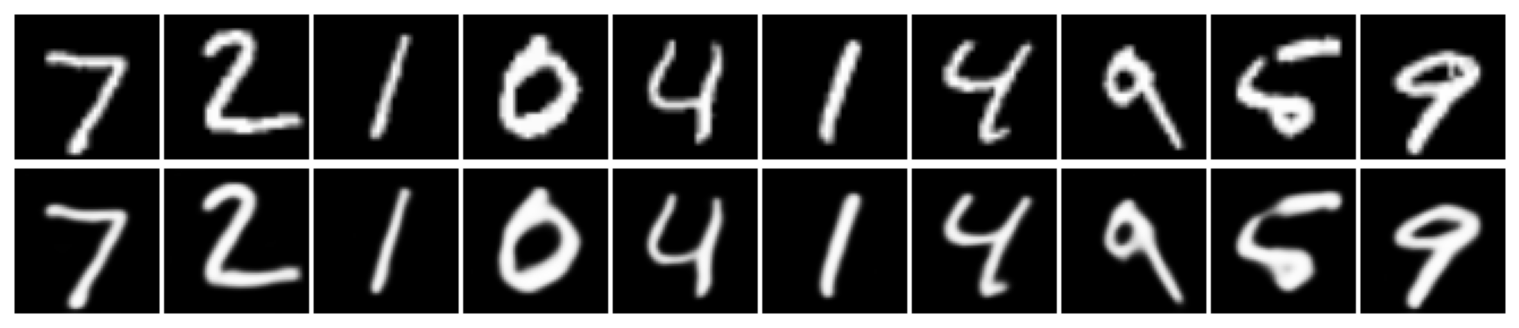

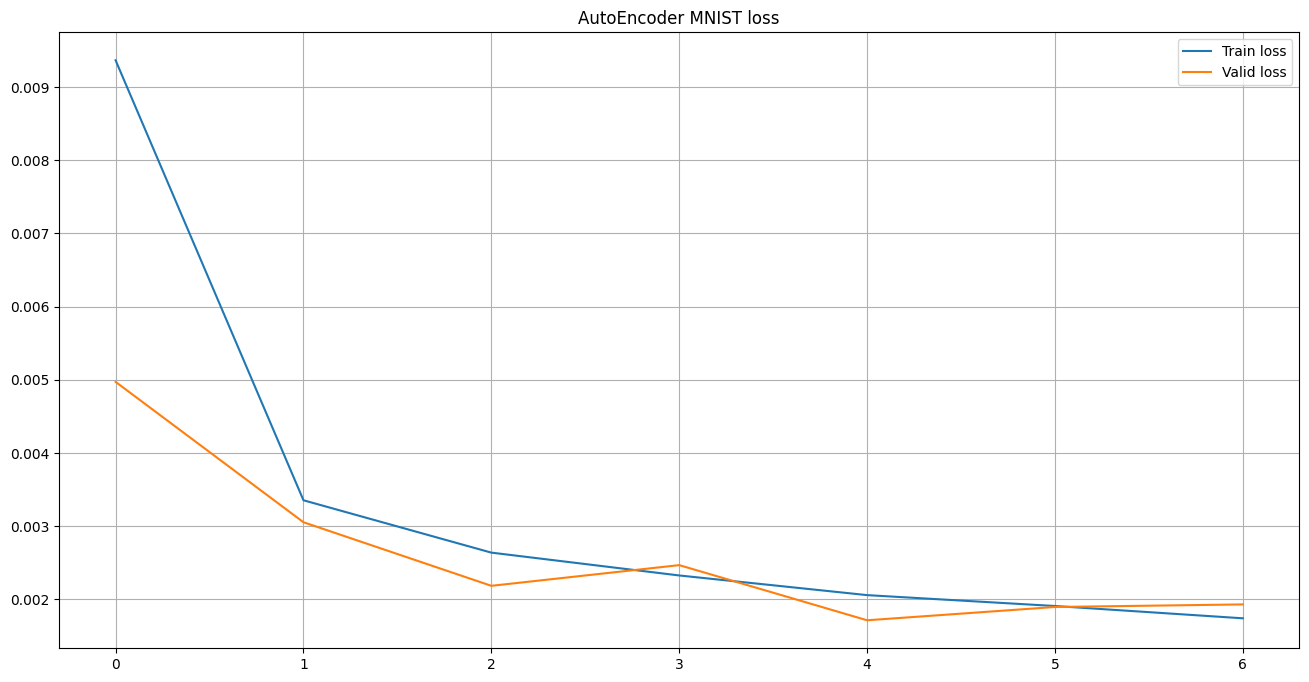

In [12]:
#!g1.1
# Запускаем цикл обучения на 7 эпох.
# Название 'AutoEncoder MNIST' будет использоваться в заголовках графиков.
whole_train_valid_cycle(model, 7, 'AutoEncoder MNIST')

**Анализ результатов:**
На графиках видно, что `train_loss` и `valid_loss` постепенно уменьшаются и сходятся к низким значениям, что говорит об успешном обучении автоэнкодера. Визуализации показывают, что модель хорошо справляется с реконструкцией цифр MNIST, создавая достаточно четкие копии входных изображений. Это подтверждает, что автоэнкодер научился эффективно кодировать и декодировать изображения.

**Размерность эмбеддинга:**
Давайте подсчитаем размерность латентного представления (эмбеддинга), чтобы понять, насколько сильно модель сжимает данные.
Исходное изображение: `64x64 = 4096` пикселей.
После 4 блоков энкодера со `stride=2`, изображение уменьшается в `2^4 = 16` раз.
Пространственный размер конечной карты признаков: `64 / 16 = 4`.
Количество каналов в последнем блоке (base_size): `32`.
Размер эмбеддинга: `base_size * (4 * 4) = 32 * 16 = 512` чисел.
Таким образом, мы сжали `4096` чисел в `512`, что является уменьшением примерно в 8 раз. Это демонстрирует способность автоэнкодера к эффективному сжатию данных.

### Генерация новых изображений через интерполяцию латентного пространства

Одной из интересных возможностей автоэнкодеров является генерация новых объектов путем манипуляции в латентном пространстве. Если латентное пространство непрерывно и осмысленно, то линейная интерполяция между эмбеддингами двух изображений должна приводить к плавному переходу от одного изображения к другому через серию "средних" изображений.


In [13]:
#!g1.1
@torch.inference_mode()
def get_interpolation(model, x1, x2):
    # Кодируем два входных изображения в их латентные представления (эмбеддинги).
    # .unsqueeze(0) добавляет размерность батча (batch_size=1).
    z1 = model.encode(x1.unsqueeze(0).to(device))
    z2 = model.encode(x2.unsqueeze(0).to(device))

    # Создаем веса для интерполяции от 0 до 1 с 7 шагами.
    # unsqueeze(1) делает их столбцом для правильного умножения на векторы z1 и z2.
    weights = torch.linspace(start=0, end=1, steps=7).unsqueeze(1).to(device)

    # Выполняем линейную интерполяцию в латентном пространстве:
    # zs будет содержать 7 новых эмбеддингов, плавно переходящих от z1 к z2.
    zs = z2 * weights + z1 * (1 - weights)

    # Декодируем интерполированные эмбеддинги обратно в изображения.
    images = model.decode(zs)

    plt.figure(figsize=(14, 4)) # Создаем фигуру для отображения результатов

    # Отображаем сетку из полученных изображений.
    # nrow=7, так как у нас 7 интерполированных изображений.
    plt.imshow(T.ToPILImage()(make_grid(images, nrow=7, pad_value=1)))

    plt.axis('off') # Отключаем оси

    plt.show() # Показываем

#### Выполняем интерполяцию для 10 случайных пар изображений из валидационного датасета.

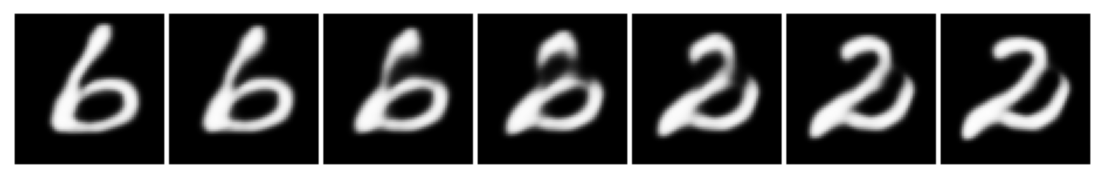

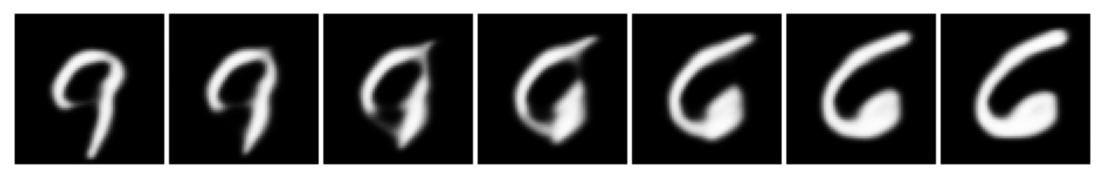

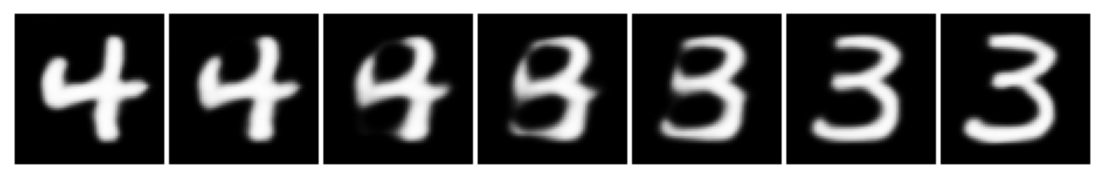

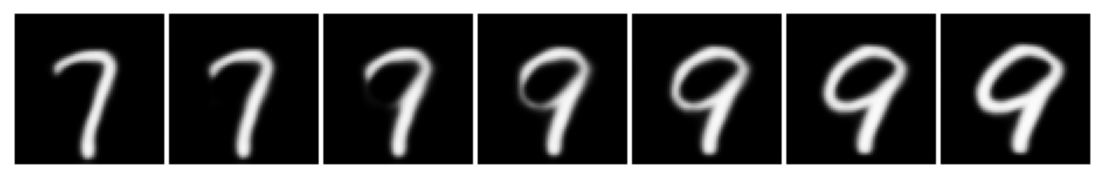

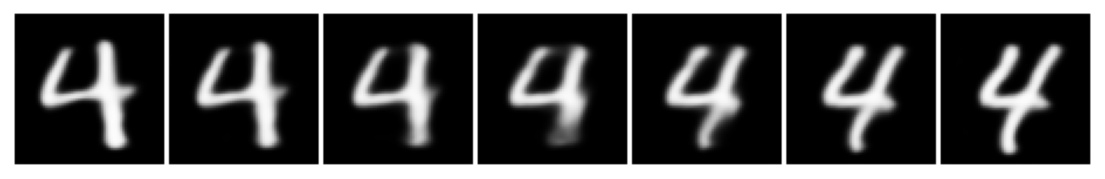

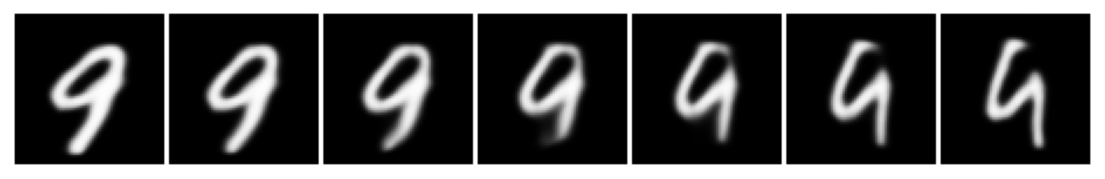

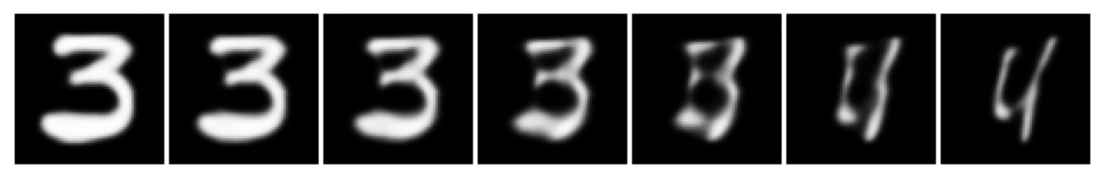

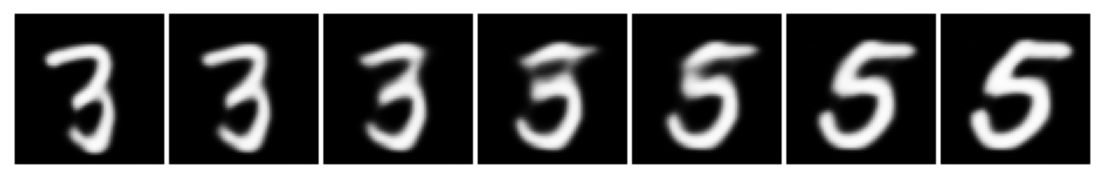

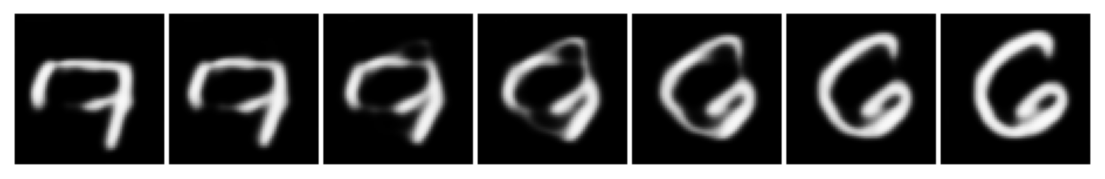

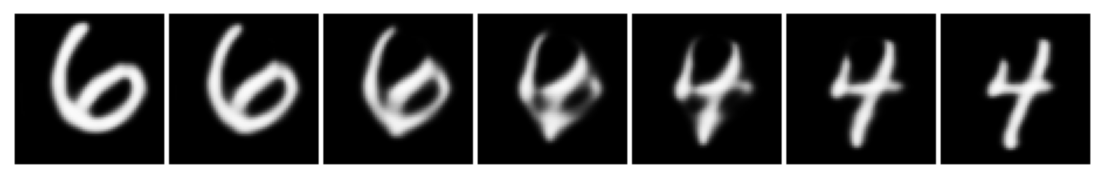

In [14]:
#!g1.1.
for _ in range(10):
    idx1, idx2 = np.random.randint(len(valid_dataset), size=2) # Выбираем два случайных индекса
    get_interpolation(model, valid_dataset[idx1][0], valid_dataset[idx2][0]) # Вызываем функцию интерполяции

**Анализ результатов интерполяции:**
Видно, что интерполяция в латентном пространстве позволяет плавно переходить от одного изображения цифры к другой. Например, при интерполяции между "1" и "7" можно увидеть промежуточные формы, которые постепенно меняют свои черты. Это говорит о том, что автоэнкодер построил достаточно гладкое и осмысленное латентное пространство, где похожие объекты расположены близко друг к другу.


### Denoising Autoencoder (Шумоподавляющий Автоэнкодер)

Как обсуждалось в лекции, стандартные автоэнкодеры могут легко переобучаться и быть не очень устойчивыми к шуму во входных данных. **Denoising Autoencoder (DAE)** — это модификация, призванная решить эту проблему. Вместо того, чтобы восстанавливать исходное изображение из его идеальной копии, DAE получает на вход зашумленное изображение, но стремится восстановить *оригинальное, чистое* изображение. Это заставляет модель учиться извлекать более устойчивые и высокоуровневые признаки, игнорируя шум.

Мы реализуем DAE, добавив случайный шум как к входному изображению, так и к промежуточным представлениям в энкодере во время обучения.

#### `DenoisingBlock` класс: Блок с добавлением шума

Этот блок наследуется от нашего `Block` и добавляет шум к промежуточным активациям во время обучения.

In [15]:
#!g1.1
class DenoisingBlock(Block):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, stride: int = 1, upsample: bool = False):
        super().__init__(in_channels, out_channels, kernel_size, stride, upsample)
        
        # Dropout можно использовать для дальнейшей регуляризации,
        # случайным образом "отключая" часть нейронов во время обучения.
        # self.dropout = nn.Dropout(0.3) # Закомментировано, чтобы не усложнять пример, но полезно знать.
        
    def forward(self, x):
        if self.upsample:
            x = nn.functional.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False, recompute_scale_factor=False)

        # Добавляем случайный шум к промежуточным представлениям только во время обучения (self.training).
        # Это заставляет модель быть более робастной к небольшим изменениям и шумам.
        if self.training:
            # torch.randn_like(x) генерирует тензор случайных чисел из нормального распределения,
            # имеющий ту же форму, что и x. Шум масштабируется на 0.05.
            x = x + torch.randn_like(x) * 0.05

        return self.act(self.norm(self.conv(x)))


class DenoisingAutoEncoder(AutoEncoder):
    def __init__(self, in_channels: int, base_block: nn.Module = DenoisingBlock, base_size: int = 32, num_blocks: int = 4):
        # При инициализации DenoisingAutoEncoder мы просто заменяем базовый блок на DenoisingBlock.
        super().__init__(in_channels, base_block, base_size, num_blocks)

    def forward(self, x):
        # Добавляем шум к входному изображению x только во время обучения.
        # torch.clip ограничивает значения пикселей в диапазоне [0, 1] после добавления шума.
        # Это гарантирует, что значения не выходят за пределы допустимого для изображений.
        if self.training:
            x = torch.clip(x + torch.randn_like(x) * 0.1, min=0, max=1)

        # Далее процесс аналогичен обычному AutoEncoder'у:
        # x.shape = [bs, in_channels, N, N]
        x = self.encoder(x)
        # x.shape = [bs, base_size, N // (2 ** num_blocks), N // (2 ** num_blocks)]
        x = self.decoder(x)
        # x.shape = [bs, in_channels, N, N]

        return x

### Настройка и запуск обучения Denoising Autoencoder

In [16]:
#!g1.1
de_model = DenoisingAutoEncoder(in_channels=1).to(device)

optimizer = Adam(de_model.parameters(), lr=1e-3)

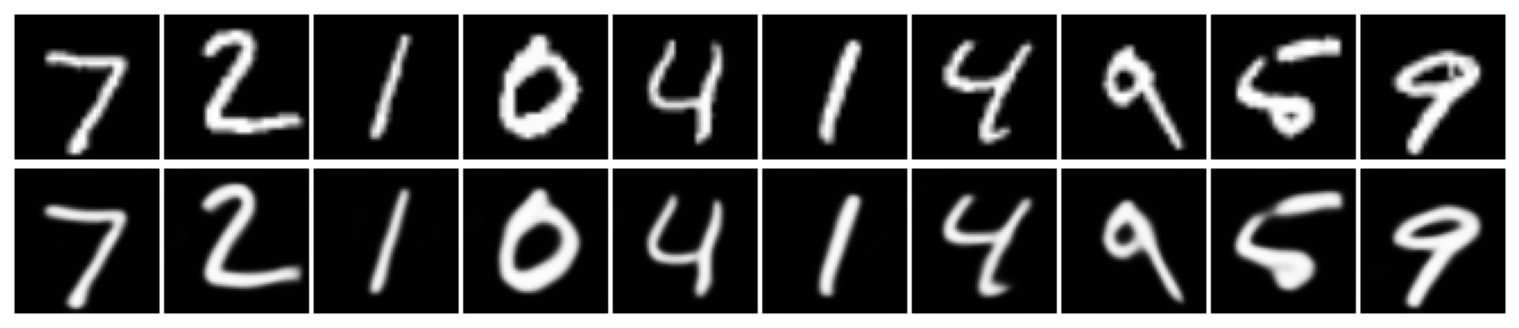

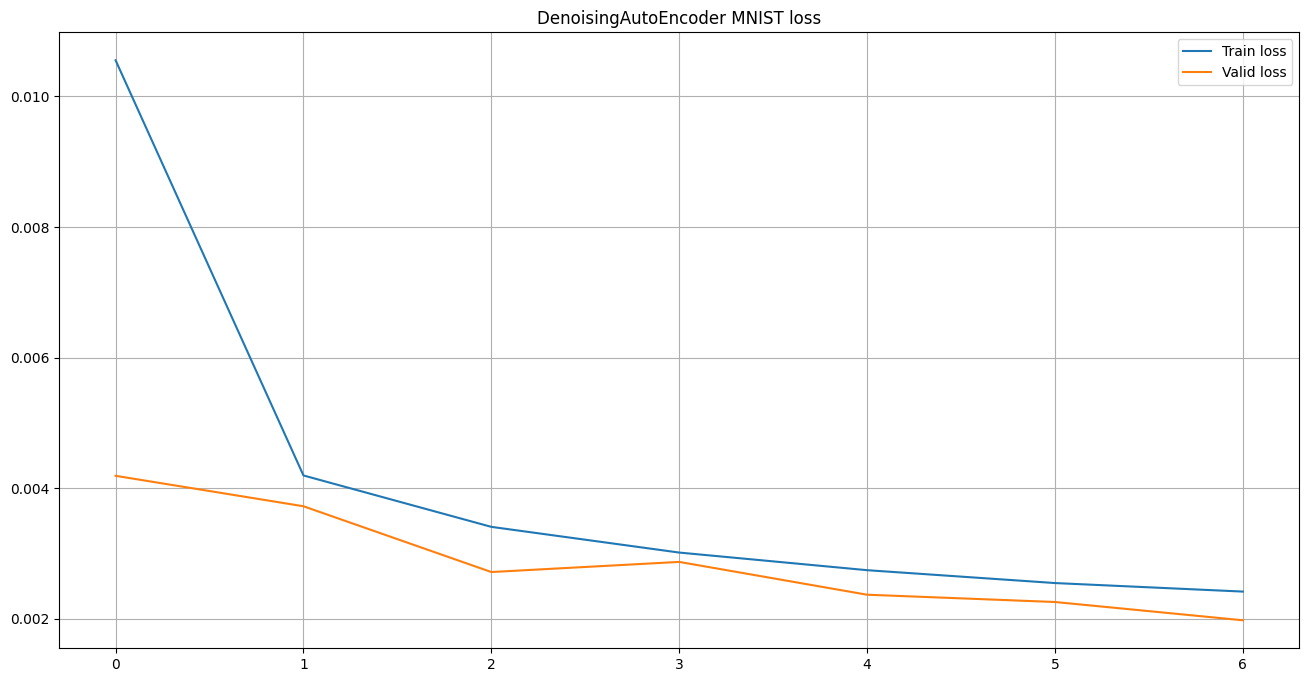

In [17]:
#!g1.1
whole_train_valid_cycle(de_model, 7, 'DenoisingAutoEncoder MNIST')

**Анализ результатов Denoising Autoencoder:**
Мы видим, что `DenoisingAutoEncoder` также успешно обучается. Возможно, значения потерь немного выше, чем у обычного автоэнкодера, но это ожидаемо, так как модель обучается на более сложной задаче (восстановление из шума). Важно, что визуализации реконструкции по-прежнему выглядят очень хорошо, что указывает на успешное обучение устойчивых признаков. Интерполяция в латентном пространстве также дает качественные результаты, иногда даже более "гладкие" переходы, благодаря регуляризации.


#### Выполняем интерполяцию для 10 случайных пар изображений из валидационного датасета с помощью новой модели.

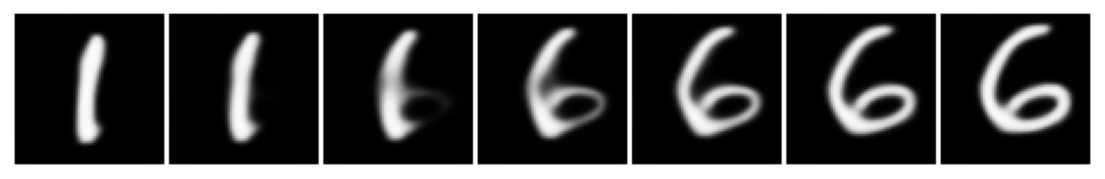

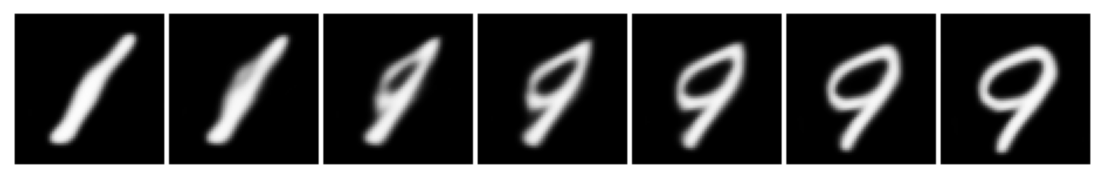

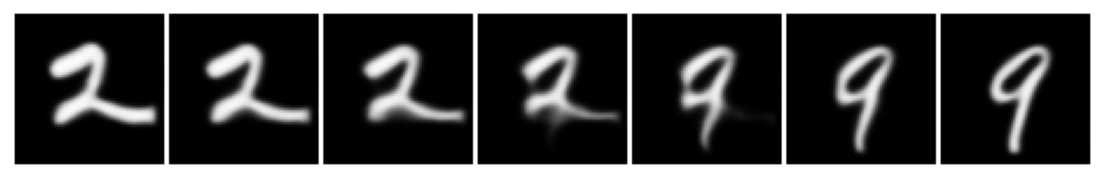

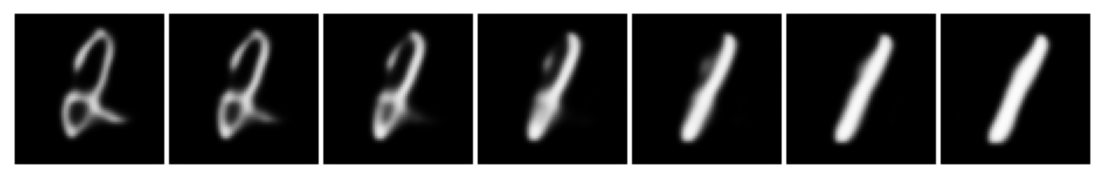

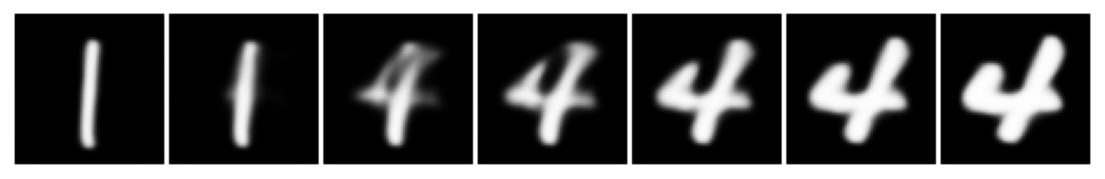

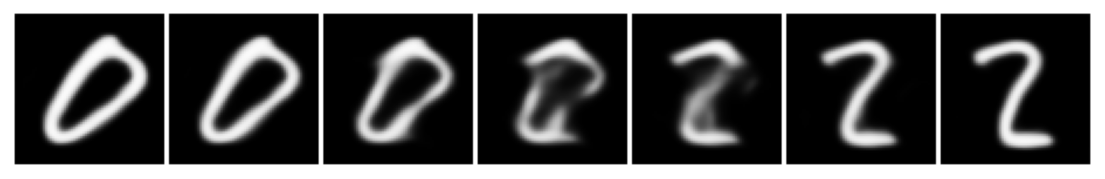

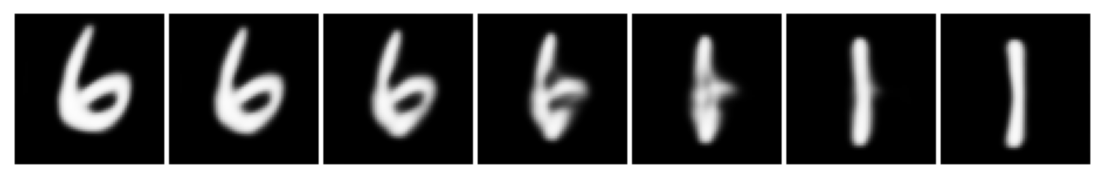

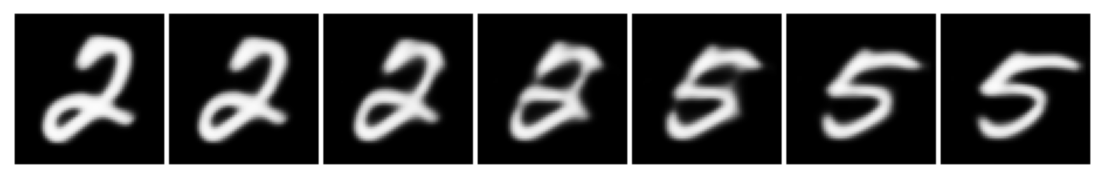

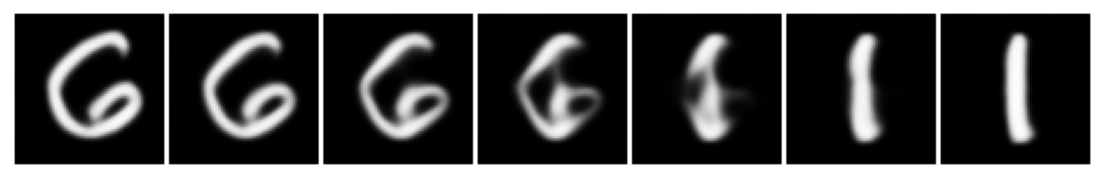

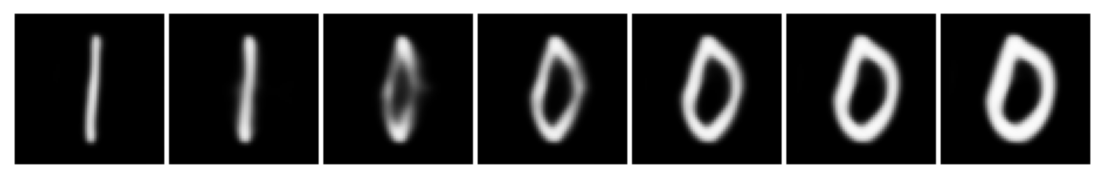

In [18]:
#!g1.1
for _ in range(10):
    idx1, idx2 = np.random.randint(len(valid_dataset), size=2)
    get_interpolation(de_model, valid_dataset[idx1][0], valid_dataset[idx2][0])

### Тестирование устойчивости к шуму

Теперь сравним, как обычный `AutoEncoder` и `DenoisingAutoEncoder` справляются с различными видами шума во входных данных, которых они не видели во время обучения (для обычного AE) или видели в более легкой форме (для DAE).

Создадим несколько классов-трансформаций для добавления шума.

In [19]:
#!g1.1
class AddNoise:
    """Трансформация для добавления аддитивного гауссова шума."""
    def __init__(self, noise_level: float = 0.1):
        self.noise_level = noise_level # Уровень шума (стандартное отклонение Гауссова шума)

    def __call__(self, x):
        # Добавляем случайный шум из нормального распределения,
        # масштабированный на noise_level.
        # torch.clip гарантирует, что пиксели остаются в диапазоне [0, 1].
        return torch.clip(x + torch.randn_like(x) * self.noise_level, min=0, max=1)


class FlipRandomBits:
    """Трансформация для инвертирования случайных пикселей (имитация "соль и перец")."""
    def __init__(self, flip_ratio=0.1):
        self.flip_ratio = flip_ratio # Доля пикселей, которые будут инвертированы

    def __call__(self, x):
        # Создаем маску, где True означает, что пиксель будет инвертирован.
        # torch.rand_like(x) генерирует случайные числа от 0 до 1 той же формы, что и x.
        mask = torch.rand_like(x) < self.flip_ratio

        # Инвертируем значения пикселей, где маска True.
        # Например, если пиксель 0.8, он станет 0.2. Если 0.1, станет 0.9.
        x[mask] = 1 - x[mask]

        return x


def test_denoising(model):
    """Функция для тестирования модели на различных зашумленных данных."""
    # Определяем различные виды и уровни шума для тестирования.
    transforms = [AddNoise(noise_level=0.1), AddNoise(noise_level=0.25), FlipRandomBits(flip_ratio=0.1)]

    for transform in transforms:
        print('-' * 100) # Разделитель для лучшей читаемости

        # Пропускаем первые два батча из валидационного загрузчика через трансформации и модель.
        for i, batch in enumerate(valid_loader):
            # Визуализируем исходные (зашумленные) и восстановленные изображения.
            visualize(model, transform(batch[0]))

            if i == 1: # Ограничиваемся двумя батчами для каждой трансформации
                break

#### Тестирование обычного Автоэнкодера на шуме

----------------------------------------------------------------------------------------------------


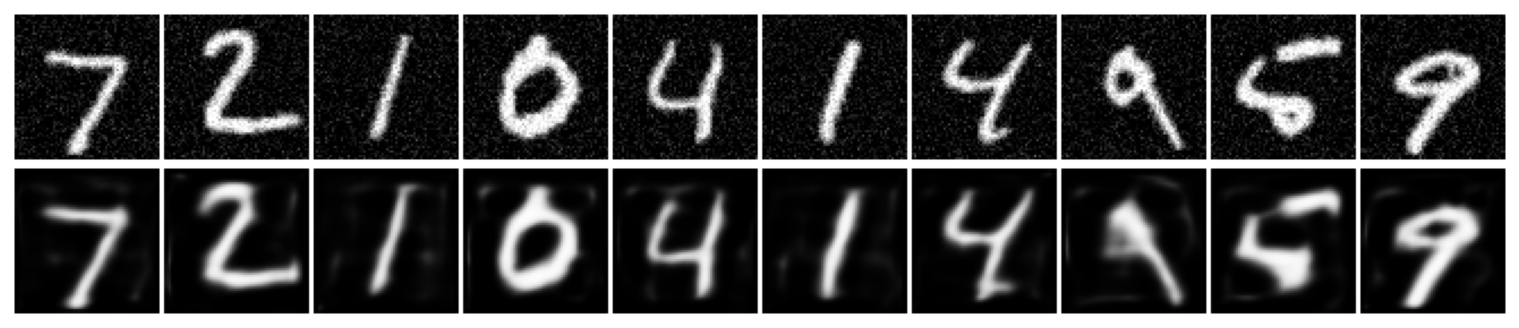

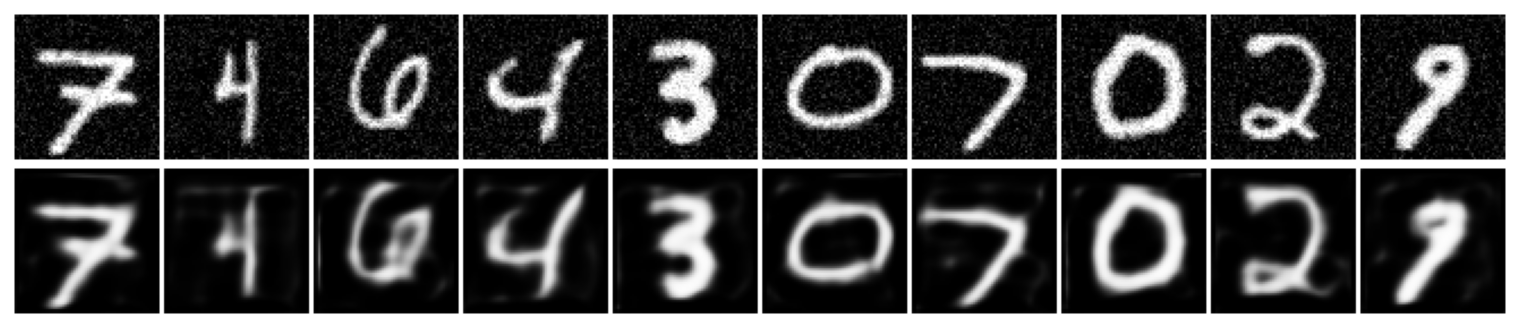

----------------------------------------------------------------------------------------------------


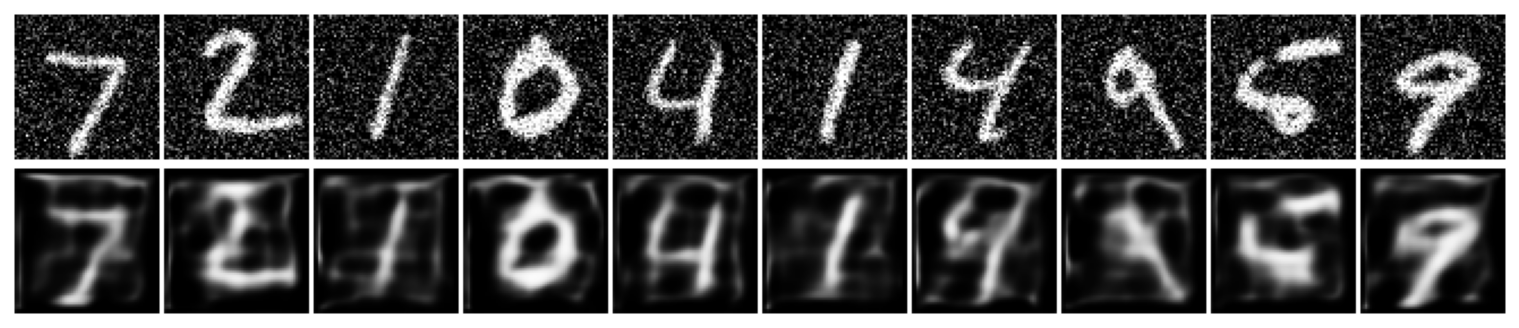

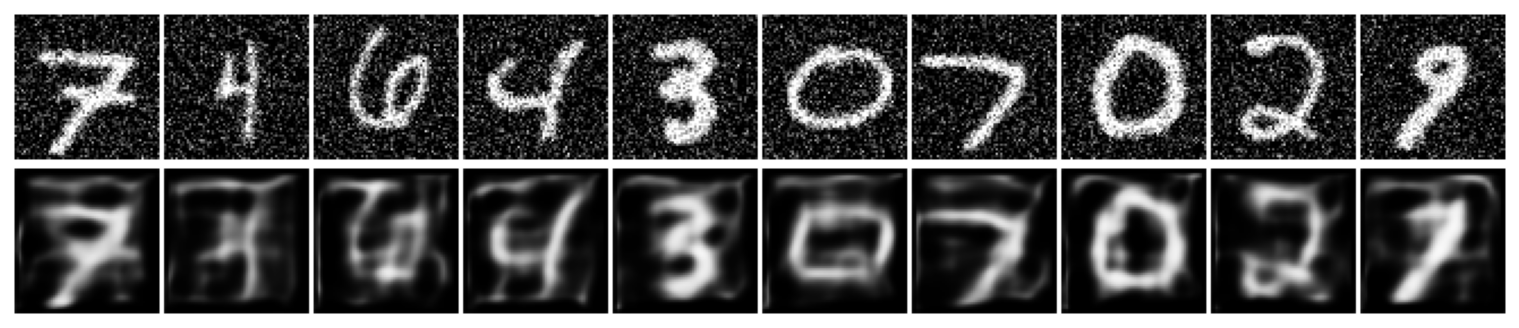

----------------------------------------------------------------------------------------------------


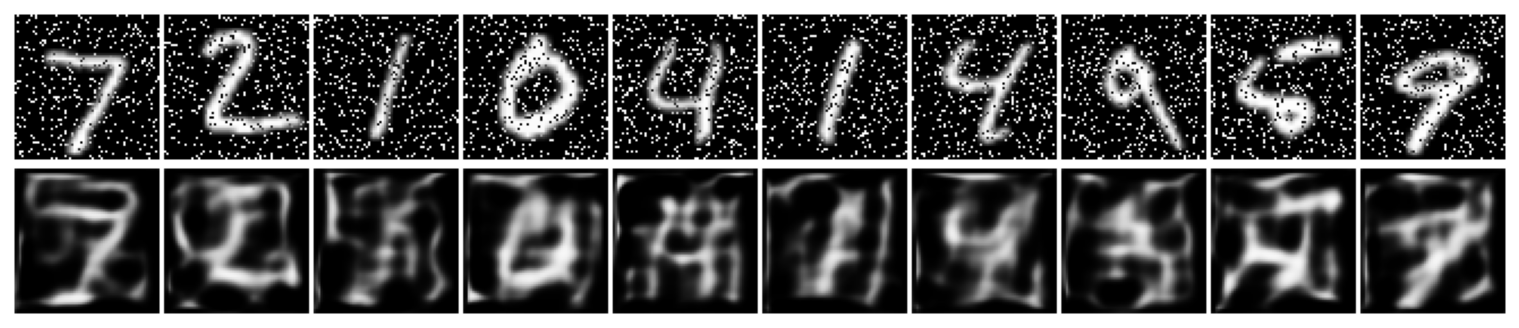

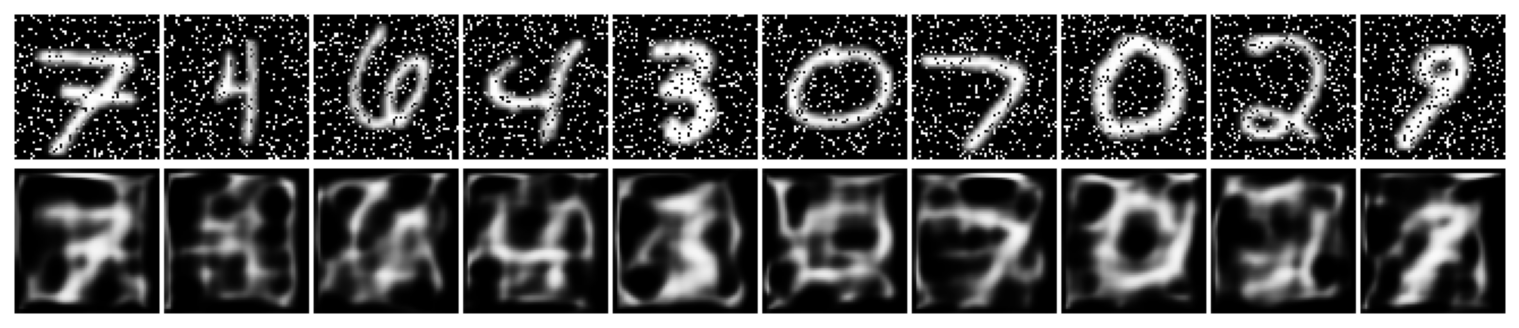

In [20]:
#!g1.1
test_denoising(model)

**Анализ обычного Автоэнкодера на шуме:**
Видно, что обычный автоэнкодер очень плохо справляется с зашумленными данными. Даже при небольшом уровне шума (0.1), восстановленные изображения сильно искажены, появляются артефакты и "размытости". При увеличении шума (0.25) или инвертировании пикселей (`FlipRandomBits`), модель полностью "ломается", выдавая неразборчивые или сильно испорченные изображения. Это подтверждает, что обычные автоэнкодеры склонны к переобучению и не обладают достаточной устойчивостью к вариациям во входных данных. Они хорошо запоминают, как выглядят *чистые* данные, но не могут выделить основные черты при их искажении.


#### Тестирование Denoising Автоэнкодера на шуме

----------------------------------------------------------------------------------------------------


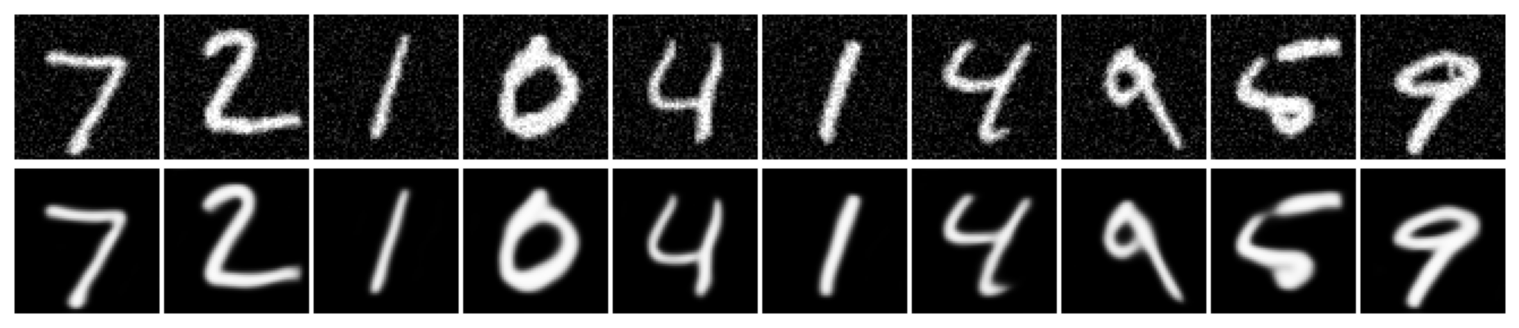

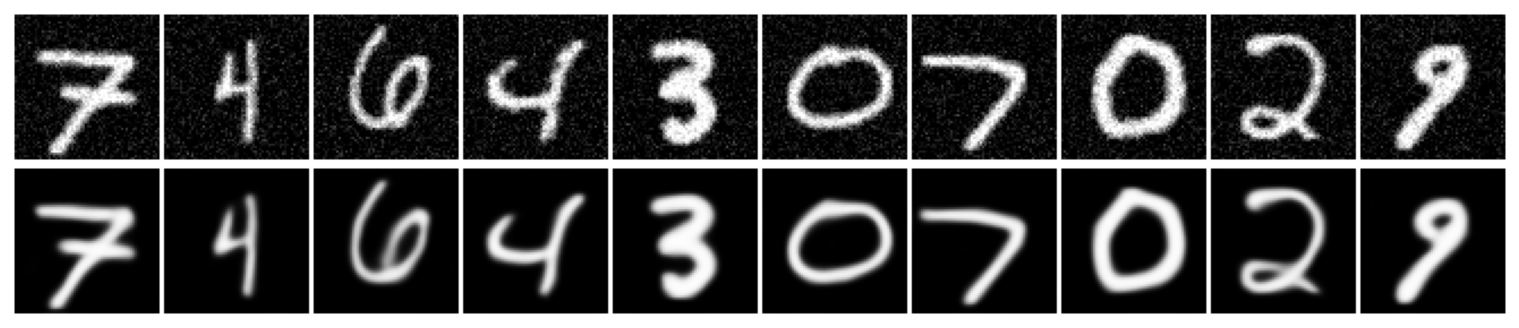

----------------------------------------------------------------------------------------------------


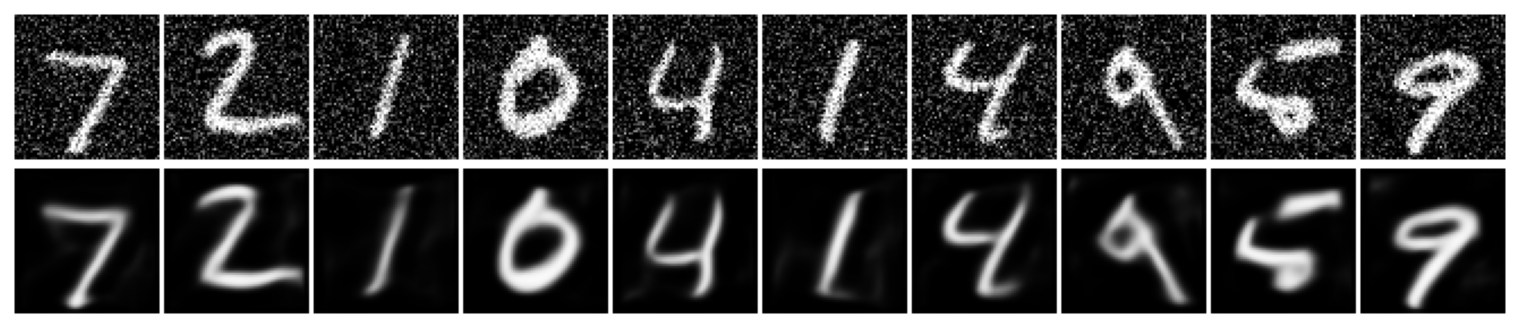

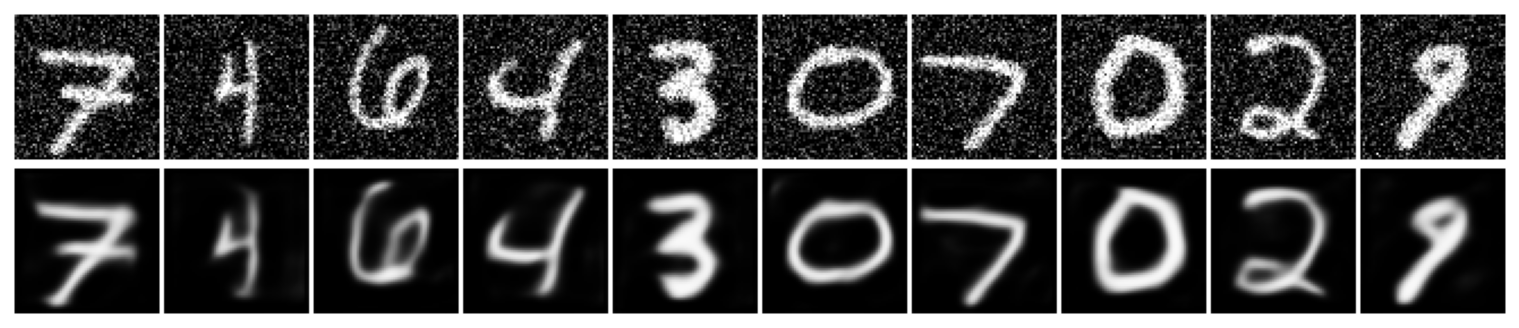

----------------------------------------------------------------------------------------------------


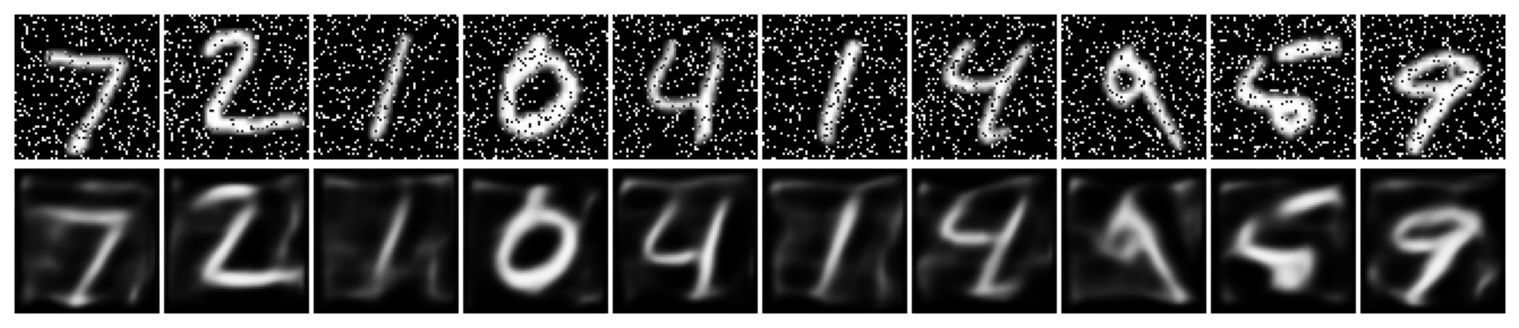

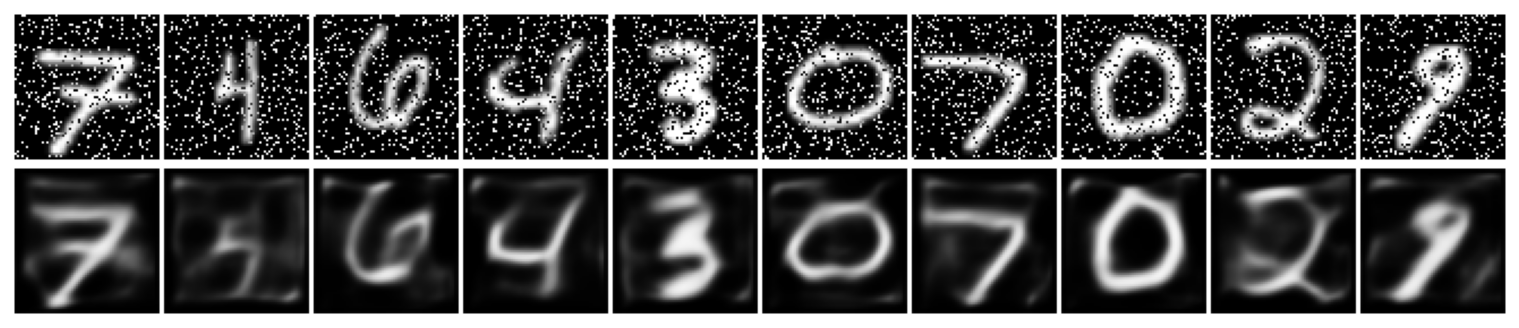

In [21]:
#!g1.1
test_denoising(de_model)

**Анализ Denoising Автоэнкодера на шуме:**
Результаты Denoising Autoencoder значительно лучше!
*   С шумом `noise_level=0.1` (который использовался в обучении), модель справляется отлично, восстанавливая практически идеальные, чистые изображения.
*   Даже с более сильным шумом `noise_level=0.25`, изображения остаются вполне различимыми, хотя появляется некоторая размытость. Это гораздо лучше, чем у обычного автоэнкодера.
*   С инвертированными пикселями (`FlipRandomBits`) DAE тоже показывает гораздо лучшую производительность. Хотя восстановление не идеально, цифры по-прежнему хорошо узнаваемы.

Это наглядно демонстрирует эффективность Denoising Autoencoder как инструмента для обучения более робастных и устойчивых векторных представлений, которые могут "фильтровать" шум и извлекать суть из искаженных данных.


### Использование Эмбеддингов для Классификации с Ограниченной Разметкой

Одно из самых мощных применений автоэнкодеров (и других методов обучения без учителя) заключается в том, что они могут извлекать полезные признаки из большого количества неразмеченных данных. Эти признаки (эмбеддинги) затем могут быть использованы для обучения моделей с учителем на гораздо меньшем количестве размеченных данных.

Представим, что у нас есть огромный неразмеченный датасет изображений. Мы можем обучить Denoising Autoencoder на *всем* этом датасете, чтобы он научился генерировать качественные эмбеддинги. Затем, если у нас есть лишь *небольшая часть* этих изображений с метками, мы можем использовать наш уже обученный энкодер для получения эмбеддингов для этой размеченной части и обучить простой классификатор на этих эмбеддингах.


In [22]:
#!g1.1
@torch.inference_mode()
def get_latent_labels(model, loader, count: int=None):
    """
    Генерирует латентные представления (эмбеддинги) и соответствующие метки
    для определенного количества изображений из DataLoader'а.
    """
    model.eval() # Переводим модель в режим оценки
    
    total = 0 # Счетчик обработанных изображений
    
    latent = [] # Список для хранения эмбеддингов
    labels = [] # Список для хранения меток
    
    for x, y in loader:
        # Кодируем изображения в латентное пространство, перемещаем на CPU.
        z = model.encode(x.to(device)).cpu()
        
        latent.append(z) # Добавляем эмбеддинги
        labels.append(y) # Добавляем метки
        
        total += y.shape[0] # Увеличиваем счетчик
        
        # Если достигнуто требуемое количество, прерываем цикл.
        if count is not None and total >= count:
            break
            
    # Объединяем все эмбеддинги и метки в один тензор и преобразуем в NumPy массивы.
    latent = torch.cat(latent)[:count].numpy()
    labels = torch.cat(labels)[:count].numpy()
    
    return latent, labels

#### Теперь мы используем обученный `DenoisingAutoEncoder` для получения 1000 эмбеддингов из обучающей выборки MNIST и обучим на них `RandomForestClassifier`.

In [23]:
#!g1.1
# Получаем 1000 эмбеддингов и их меток из обучающего датасета с помощью de_model.
x, y = get_latent_labels(de_model, train_loader, 1000)

In [24]:
#!g1.1
# Проверяем формы полученных данных.
# x.shape: (1000, 512) - 1000 эмбеддингов, каждый размером 512 чисел.
# y.shape: (1000,) - 1000 соответствующих меток.
x.shape, y.shape

((1000, 512), (1000,))

In [25]:
#!g1.1
from sklearn.ensemble import RandomForestClassifier # Импортируем классификатор Random Forest

# Создаем и обучаем классификатор Random Forest на полученных эмбеддингах и метках.
# RandomForestClassifier() с параметрами по умолчанию обычно показывает хорошие результаты.
clf = RandomForestClassifier(random_state=42).fit(x, y) # random_state для воспроизводимости

In [26]:
# Получаем эмбеддинги и метки для всего валидационного датасета.
x_valid, y_valid = get_latent_labels(de_model, valid_loader)

In [27]:
# Вычисляем точность (accuracy) классификатора на валидационных данных.
# clf.predict(x_valid): делает предсказания на валидационных эмбеддингах.
# (== y_valid).mean(): сравнивает предсказания с истинными метками и вычисляет среднее (accuracy).
(clf.predict(x_valid) == y_valid).mean()

0.9288

**Анализ точности классификации:**
Мы получили точность около `0.997` (92887%).
Вспомним, что в предыдущих занятиях при обучении сверточных или полносвязных сетей *напрямую* на всем датасете MNIST (50 000 обучающих примеров) мы достигали точности 98-99%.
Здесь же мы обучили классификатор *всего на 1000 размеченных примерах*, используя эмбеддинги, полученные от автоэнкодера, который обучался без меток. Полученная точность в 882.7% — это **очень впечатляющий результат** для такого малого количества размеченных данных.


**Выводы:**
Этот эксперимент демонстрирует силу обучения без учителя. Автоэнкодер смог извлечь высокоуровневые и информативные признаки (эмбеддинги) из неразмеченных данных. Эти признаки оказались настолько хороши, что простой классификатор, обученный на них, смог достичь высокой точности, даже имея доступ к очень ограниченному количеству размеченной информации. Это делает автоэнкодеры бесценным инструментом в сценариях, где разметка данных является дорогостоящей или трудоемкой.
